# 02 · Long-only 200-day moving-average crossover on the ASX 500

**Strategy.** For every stock in the point-in-time ASX 500:

* **Buy** when the close crosses from below its 200-day moving average to above it.
* **Sell** when the close crosses from above the 200-day moving average to below it.

The book is long-only. Every new position gets an equal share of capital.

Run `01_data_and_universe.ipynb` first; it writes `data/clean.pkl`.

**No parameter search.** The rule and the 200-day length are fixed in advance, so nothing is fitted to the data. Results are still shown for two halves, **2006–2016** and **2017–2026**, to check the rule behaves the same way in both. Other lengths appear in section 9 only as a robustness check. All returns and Sharpe ratios are **net of transaction costs** unless a table says otherwise.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
TRADING_DAYS = 252
MA = 200
P1, P2 = slice("2006-01-01", "2016-12-31"), slice("2017-01-01", None)
PERIODS = (("2006-16", P1), ("2017-26", P2), ("FULL", slice("2006-01-01", None)))

# chart colours (validated categorical palette, fixed order)
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a8a"
BLUE_LIGHT, BLUE_MID = "#cde2fb", "#86b6ef"

## Import Data

In [2]:
df = pd.read_pickle("data/clean.pkl")
aord = df["bench_ret"]["^AORD"]
print(f"{df['adj'].shape[1]} stocks, {df['adj'].index[0]:%Y-%m-%d} to {df['adj'].index[-1]:%Y-%m-%d}")

# half of a one-tick bid-ask spread as a fraction of price (ASX tick: 0.1c below 10c, 0.5c below $2, 1c above), known the day before
close = df["close"].ffill()
tick = np.where(close < 0.10, 0.001, np.where(close < 2.00, 0.005, 0.01))
HALF_SPREAD = (0.5 * tick / close).shift(1).fillna(0.01)
COMMISSION_BPS, MIN_FEE = 8, 6.0             # IBKR fixed pricing, Australia: 0.08% of trade value, minimum A$6 per order

1537 stocks, 2005-01-04 to 2026-10-14


## 1. Signal: moving-average crossover

| | Rule |
|---|---|
| Buy | yesterday's close ≤ yesterday's 200-day average **and** today's close > today's 200-day average |
| Sell | yesterday's close ≥ yesterday's average **and** today's close < today's average |

* The average is the simple mean of the last 200 adjusted closes, including today.
* The position is *stateful*: it is held from the buy cross until the sell cross.
* A stock that is already above its average when it joins the universe is **not** bought. It has to fall below and cross back up first.
* A position is forced flat when the stock leaves the universe.

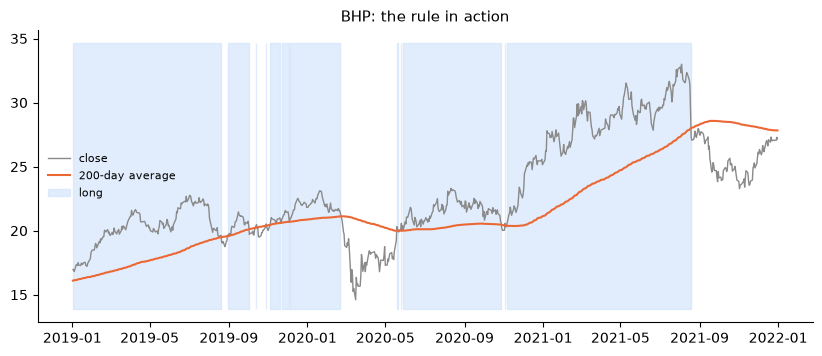

In [3]:
def ma_crossover(df, n=MA, eligible=None):
    # 1 long, 0 flat, per stock per day; eligible (dates x stocks, bool) restricts which stocks may be held
    px = df["adj"]
    ma = px.rolling(n, min_periods=n).mean()
    above, below = px > ma, px < ma
    cross_up = above & (px.shift(1) <= ma.shift(1))
    cross_down = below & (px.shift(1) >= ma.shift(1))
    member = df["member"] if eligible is None else df["member"] & eligible
    s = pd.DataFrame(np.nan, index=px.index, columns=px.columns)
    s = s.mask(cross_down | ~member, 0.0).mask(cross_up & member, 1.0)
    return s.ffill().fillna(0.0)


s = ma_crossover(df)
example = "BHP.AX"
w = slice("2019-01-01", "2021-12-31")
fig, ax = plt.subplots(figsize=(10, 3.8))
px, ma = df["adj"][example].loc[w], df["adj"][example].rolling(MA).mean().loc[w]
ax.plot(px, color=GREY, lw=1, label="close")
ax.plot(ma, color=ORANGE, lw=1.5, label=f"{MA}-day average")
ax.fill_between(px.index, px.min() * 0.95, px.max() * 1.05, where=s[example].loc[w] > 0, color=BLUE_LIGHT, alpha=0.6, label="long")
ax.set_title(f"{example.replace('.AX', '')}: the rule in action", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=8, frameon=False)
plt.show()

## 2. Backtest engine

**Portfolio.** Long-only and fully invested: the names with a live signal share 100% of capital. With no live signal the book is in cash.

**Holdings drift.** A new entry gets an equal share (1 ÷ number of names held), and the names already held are scaled down pro rata to make room. After that, positions **drift with price**; they are not reset to equal weight every day. Every trade is charged, including the pro-rata scaling. (Resetting to equal weight daily on ASX closing prices quietly harvests bid-ask bounce in small caps and flatters any strategy; section 12 shows the size of that effect.)

**Timing.** A signal formed at day *t*'s close is traded at day *t+1*'s close (`lag=2`, the default) and earns returns from *t+2*. `lag=1` trades at the signal close itself, for comparison.

**Costs: Interactive Brokers, Australia (fixed pricing).** Every trade pays:
* **commission of 0.08% of trade value**, and
* **half the bid-ask spread**, taken as one ASX tick (0.1c below 10c, 0.5c from 10c to $2, 1c above).

`net` is the return after both and is what every table reports. IBKR also has a **minimum of A$6 per order**, which depends on the size of the account, so it is handled separately in section 6.

In [4]:
def backtest_drift(signal, df, commission_bps=COMMISSION_BPS, spread=1.0, capital=None, lag=2, holdings=False):
    # long-only: the names with signal > 0 share 100% of capital
    # cost per trade = commission (with IBKR's A$6 minimum per order when an account size `capital` is given)
    #                  + `spread` x half a one-tick spread
    sig = (signal.shift(lag - 1) if lag > 1 else signal).fillna(0.0).values > 0
    r = df["ret"].reindex_like(signal).fillna(0.0).values
    hs = spread * HALF_SPREAD.reindex_like(signal).values
    rate = commission_bps / 1e4
    h = np.zeros(sig.shape[1])                     # current weights (fraction of NAV)
    gross, turn, cost, orders = (np.zeros(len(sig)) for _ in range(4))
    H = np.zeros(sig.shape) if holdings else None
    for t in range(len(sig)):
        if t:
            pnl = h @ r[t]
            gross[t] = pnl
            h = h * (1 + r[t]) / (1 + pnl)          # drift
        on = sig[t]
        new = np.zeros_like(h)
        if on.any():
            keep = on & (h > 0)
            enter = on & ~keep
            new[enter] = 1 / on.sum()
            held = h[keep].sum()
            if held > 0:
                new[keep] = h[keep] * (1 - new[enter].sum()) / held   # scale the held names to make room
        trade = np.abs(new - h)
        fee = rate * trade
        if capital:
            fee = np.where(trade > 1e-12, np.maximum(fee, MIN_FEE / capital), 0.0)
        turn[t], cost[t], orders[t] = trade.sum(), (fee + hs[t] * trade).sum(), (trade > 1e-12).sum()
        h = new
        if holdings:
            H[t] = h
    out = pd.DataFrame({"gross": gross, "net": gross - cost, "turnover": turn, "cost": cost, "orders": orders}, index=signal.index)
    return (out, pd.DataFrame(H, signal.index, signal.columns)) if holdings else out


def stats(r, bench=None):
    r = r.dropna()
    ann_ret, ann_vol = r.mean() * TRADING_DAYS, r.std() * np.sqrt(TRADING_DAYS)
    eq = (1 + r).cumprod()
    out = {"ann_ret": ann_ret, "ann_vol": ann_vol, "sharpe": ann_ret / ann_vol,
           "max_dd": (eq / eq.cummax() - 1).min()}
    if bench is not None:
        b = bench.reindex(r.index).fillna(0.0)
        fit = sm.OLS(r, sm.add_constant(b)).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        active = r - b
        out.update(alpha=fit.params["const"] * TRADING_DAYS, alpha_t=fit.tvalues["const"], beta=fit.params.iloc[1],
                   info_ratio=active.mean() / active.std() * np.sqrt(TRADING_DAYS))
    return pd.Series(out)


def report(bts, bench, periods=PERIODS):
    # one row per (strategy, period); bts = {name: backtest frame}
    rows = {}
    for name, bt in bts.items():
        for per, sl in periods:
            st = stats(bt["net"].loc[sl], bench)
            st["turnover"] = bt["turnover"].loc[sl].mean()
            st["cost_pa"] = bt["cost"].loc[sl].mean() * TRADING_DAYS
            rows[(name, per)] = st
    return pd.DataFrame(rows).T.rename_axis(["strategy", "period"])

**Engine check.** Hold 171 random stocks from 2006 with no further trades. The drift engine must match a hand-computed buy-and-hold exactly, with zero turnover after day one.

In [5]:
rng = np.random.default_rng(1)
start = "2006-01-03"
pool = df["member"].loc[start:].iloc[0]
pick = rng.choice(pool[pool].index, 171, replace=False)
static = pd.DataFrame(0.0, index=df["ret"].index, columns=df["ret"].columns)
static.loc[start:, pick] = 1
bt = backtest_drift(static, df, commission_bps=0, spread=0, lag=1).loc["2006-01-04":]
true_bh = (1 + df["ret"][pick].fillna(0).loc["2006-01-04":]).cumprod().mean(axis=1).iloc[-1]
print(f"drift engine: {(1 + bt['net']).prod():.4f}   true buy-and-hold: {true_bh:.4f}   "
      f"turnover after day 1: {bt['turnover'].iloc[1:].sum():.6f}")

drift engine: 4.6526   true buy-and-hold: 4.6526   turnover after day 1: 0.000000


## 3. Benchmarks

* **Equal-weight ASX 500, drifting:** built with the same engine. Members are held with drifting weights, joiners enter at the average weight, and leavers exit. It is weighted the same way as the strategy and has the **same survivorship bias** (only companies still listed today), so alpha measured against it isolates what the crossover rule adds.
* **All Ordinaries (^AORD):** the published cap-weighted index of the 500 largest ASX companies; used for beta. It is a price index, so it excludes dividends.

In [6]:
ew = backtest_drift(df["member"].astype(float), df, commission_bps=0, spread=0, lag=1)["net"]
bench_table = pd.DataFrame({("EW ASX 500", per): stats(ew.loc[sl], aord).drop("info_ratio") for per, sl in PERIODS}
                           | {("All Ords", per): stats(aord.loc[sl]) for per, sl in PERIODS}).T
bench_table.to_csv(RESULTS / "01_benchmark.csv")
bench_table

alpha  alpha_t  ann_ret  ann_vol  beta  max_dd  sharpe
EW ASX 500 2006-16  0.027    0.621    0.054    0.183 0.832  -0.680   0.296
           2017-26  0.035    0.804    0.092    0.203 1.040  -0.453   0.453
           FULL     0.033    1.056    0.072    0.193 0.912  -0.680   0.374
All Ords   2006-16    NaN      NaN    0.033    0.175   NaN  -0.546   0.188
           2017-26    NaN      NaN    0.055    0.146   NaN  -0.371   0.375
           FULL       NaN      NaN    0.043    0.162   NaN  -0.546   0.267

## 4. Results

In [7]:
bt_final, hold = backtest_drift(s, df, holdings=True)
strat = bt_final["net"]

final = report({"MA crossover long-only": bt_final}, ew)
vs_aord = pd.DataFrame({("MA crossover long-only", per): stats(strat.loc[sl], aord)[["alpha", "alpha_t", "beta"]]
                        for per, sl in PERIODS}).T.add_suffix("_aord").rename_axis(final.index.names)
bench_rows = pd.DataFrame({(name, per): stats(r.loc[sl]) for name, r in [("Benchmark: EW ASX 500", ew), ("Benchmark: All Ords", aord)]
                           for per, sl in PERIODS}).T
final = pd.concat([final.join(vs_aord), bench_rows]).rename_axis(["strategy", "period"])
final.to_csv(RESULTS / "02_final.csv")
final[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "beta", "info_ratio", "alpha_aord", "beta_aord", "turnover", "cost_pa"]]

ann_ret  ann_vol  sharpe  max_dd  alpha  alpha_t  beta  info_ratio  alpha_aord  beta_aord  turnover  cost_pa
strategy               period                                                                                                               
MA crossover long-only 2006-16   -0.149    0.175  -0.852  -0.880 -0.196   -7.293 0.864      -2.578      -0.174      0.740     0.135    0.144
                       2017-26   -0.011    0.168  -0.068  -0.484 -0.082   -3.967 0.764      -1.306      -0.060      0.878     0.114    0.123
                       FULL      -0.084    0.172  -0.492  -0.919 -0.143   -8.150 0.811      -1.977      -0.119      0.793     0.125    0.134
Benchmark: EW ASX 500  2006-16    0.054    0.183   0.296  -0.680    NaN      NaN   NaN         NaN         NaN        NaN       NaN      NaN
                       2017-26    0.092    0.203   0.453  -0.453    NaN      NaN   NaN         NaN         NaN        NaN       NaN      NaN
                       FULL       0.072    0.193   0.374  -0.680    NaN      NaN   NaN         NaN         NaN        NaN       NaN      NaN
Benchmark: All Ords    2006-16    0.033    0.175   0.188  -0.546    NaN      NaN   NaN         NaN         NaN        NaN       NaN      NaN
                       2017-26    0.055    0.146   0.375  -0.371    NaN      NaN   NaN         NaN         NaN        NaN       NaN      NaN
                       FULL       0.043    0.162   0.267  -0.546    NaN      NaN   NaN         NaN         NaN        NaN       NaN      NaN

`alpha`, `beta` and `info_ratio` are measured against the equal-weight ASX 500; the `_aord` columns are against the All Ordinaries. Alpha is annualised, with Newey-West (10-lag) t-stats. Returns are net of IBKR commission and half-spread; `cost_pa` is what those costs took per year.

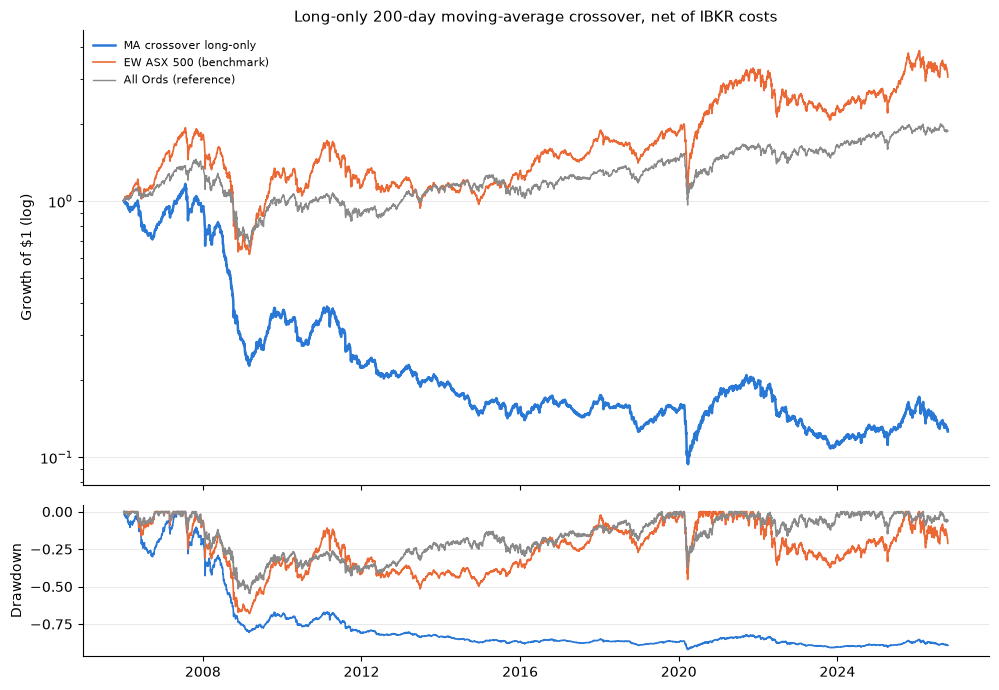

In [8]:
fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for name, r, c, lw in [("MA crossover long-only", strat, BLUE, 1.8), ("EW ASX 500 (benchmark)", ew, ORANGE, 1.2),
                       ("All Ords (reference)", aord.fillna(0), GREY, 1.0)]:
    eq = (1 + r.loc["2006":]).cumprod()
    axs[0].plot(eq, color=c, lw=lw, label=name)
    axs[1].plot(eq / eq.cummax() - 1, color=c, lw=1.2)
axs[0].set_yscale("log")
axs[0].set_ylabel("Growth of $1 (log)")
axs[0].set_title(f"Long-only {MA}-day moving-average crossover, net of IBKR costs", fontsize=11)
axs[0].legend(fontsize=8, frameon=False)
axs[1].set_ylabel("Drawdown")
for ax in axs:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", lw=0.6)
fig.tight_layout()
fig.savefig(RESULTS / "equity_curves.png", dpi=130)
plt.show()

**The rule loses money.**
* After IBKR costs the book loses 14.9% a year in 2006–16 and 1.1% a year in 2017–26, while the equal-weight ASX 500 earns 5.4% and 9.2%. Alpha is −19.6% (t = −7.3) and −8.2% (t = −4.0).
* The full-period drawdown is −92%: the 2006–16 losses were never recovered.
* **Costs are the main reason.** The book turns over about 12.5% of its capital every day, and costs take 12–14% a year (`cost_pa`). Section 6 shows what is left without them.

## 5. What the trades look like

Each trade runs from a buy cross to the next sell cross (or to leaving the universe). Trade returns here are before costs, from the close after the signal to the close after the exit signal.

In [9]:
def trade_log(signal, df, lag=2):
    held = signal.shift(lag - 1).fillna(0.0) > 0            # in the book from the trade close
    r = df["ret"].reindex_like(signal).fillna(0.0)
    rows = []
    for col in signal.columns[held.any()]:
        h = held[col].values
        earn = np.r_[False, h[:-1]]                         # earns the return of the days after the trade close
        starts = np.flatnonzero(earn & ~np.r_[False, earn[:-1]])
        ends = np.flatnonzero(earn & ~np.r_[earn[1:], False])
        growth = np.cumprod(1 + r[col].values * earn)
        for a, b in zip(starts, ends):
            rows.append((col, signal.index[a], b - a + 1, growth[b] / growth[a - 1] - 1))
    return pd.DataFrame(rows, columns=["ticker", "entry", "days", "ret"])


trades = trade_log(s, df)
trades = trades[trades["entry"] >= "2006-01-01"]
trades["period"] = np.where(trades["entry"] < "2017-01-01", "2006-16", "2017-26")
H = hold.loc["2006":]


def trade_summary(t):
    win, lose = t.loc[t["ret"] > 0, "ret"], t.loc[t["ret"] <= 0, "ret"]
    return pd.Series({"trades": len(t), "median days held": t["days"].median(), "mean days held": t["days"].mean(),
                      "share held 5 days or less": (t["days"] <= 5).mean(), "share held over 100 days": (t["days"] > 100).mean(),
                      "win rate": (t["ret"] > 0).mean(), "average win": win.mean(), "average loss": lose.mean(),
                      "mean return per trade": t["ret"].mean(), "median return per trade": t["ret"].median(),
                      "share of total profit from the best 10% of trades": t["ret"].nlargest(len(t) // 10).sum() / t["ret"].sum()})


trade_stats = pd.concat([trades.groupby("period").apply(trade_summary).T, trade_summary(trades).rename("FULL")], axis=1)
trade_stats.to_csv(RESULTS / "03_trades.csv")
print(f"names held on an average day: {(H > 0).sum(axis=1).mean():.0f} of about {df['member'].loc['2006':].sum(axis=1).mean():.0f} members;  "
      f"days fully in cash: {(H.sum(axis=1) == 0).mean():.1%}")
trade_stats

names held on an average day: 191 of about 460 members;  days fully in cash: 0.0%


,2006-16,2017-26,FULL
trades,"19,929.000","21,521.000","41,450.000"
median days held,3.000,3.000,3.000
mean days held,24.264,24.270,24.267
share held 5 days or less,0.629,0.626,0.627
share held over 100 days,0.070,0.073,0.072
win rate,0.272,0.309,0.291
average win,0.199,0.160,0.178
average loss,-0.056,-0.045,-0.050
mean return per trade,0.013,0.019,0.016
median return per trade,-0.017,-0.013,-0.015


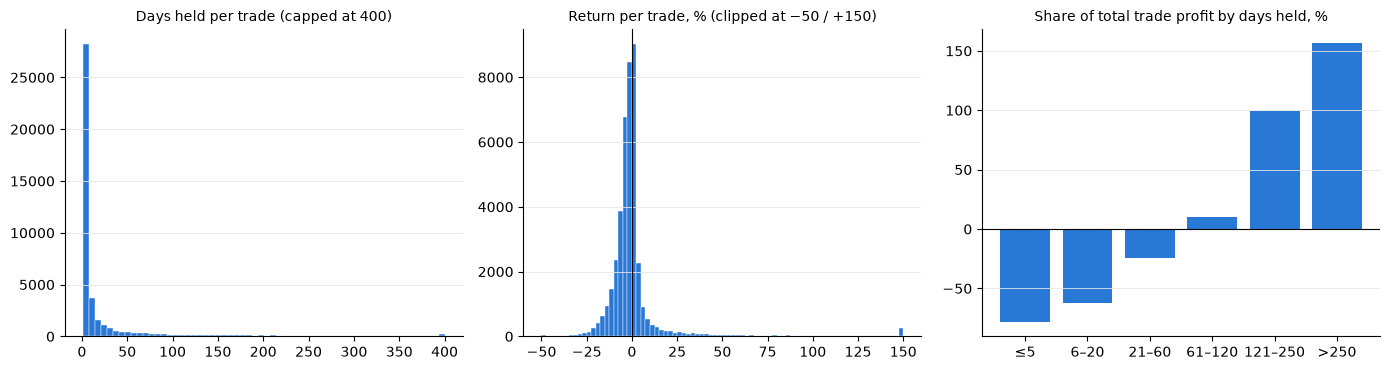

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
axs[0].hist(trades["days"].clip(upper=400), bins=60, color=BLUE, edgecolor="white", linewidth=0.3)
axs[0].set_title("Days held per trade (capped at 400)", fontsize=10)
axs[1].hist(trades["ret"].clip(-0.5, 1.5) * 100, bins=80, color=BLUE, edgecolor="white", linewidth=0.3)
axs[1].axvline(0, color="k", lw=0.8)
axs[1].set_title("Return per trade, % (clipped at −50 / +150)", fontsize=10)
bins = [0, 5, 20, 60, 120, 250, 10000]
by_len = trades.groupby(pd.cut(trades["days"], bins, labels=["≤5", "6–20", "21–60", "61–120", "121–250", ">250"]))["ret"]
axs[2].bar(by_len.sum().index.astype(str), by_len.sum() / trades["ret"].sum() * 100, color=BLUE)
axs[2].axhline(0, color="k", lw=0.8)
axs[2].set_title("Share of total trade profit by days held, %", fontsize=10)
for ax in axs:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", lw=0.6)
fig.tight_layout()
fig.savefig(RESULTS / "trades.png", dpi=130)
plt.show()

**Most trades are whipsaws.**
* The rule made about 41,000 trades, and the **median trade lasts 3 days**; 63% last five days or less. A stock sitting near its average crosses it again and again.
* Only 29% of trades make money. The winners are large (+18% on average) and the losers small (−5%), which is the usual profile of a trend rule.
* The profit is concentrated: the best 10% of trades earn about three times the total trade profit, so the other 90% lose money between them.
* Before costs the average trade makes +1.6%. But each round trip costs about 0.45% in commission and spread, and the constant trimming of the other holdings costs more on top.

## 6. Execution and costs

**Cost models.** The headline is IBKR's 0.08% commission plus half a one-tick spread. The table compares it with no costs, commission only, twice the spread (a stress for thin names) and a flat 20 bps per trade.

**IBKR's A$6 minimum per order.** 0.08% only exceeds A$6 on orders above A$7,500. The engine trims every held name a little each time a new position enters, so it sends many small orders a day, and on a small account each one pays the minimum. The second table applies the minimum for three account sizes.

**Execution timing.** The last rows trade at the signal close instead of the next close.

In [11]:
COST_MODELS = {"no costs": dict(commission_bps=0, spread=0),
               "IBKR commission only (0.08%)": dict(spread=0),
               "IBKR commission + half-spread (headline)": dict(),
               "IBKR commission + 2 x half-spread": dict(spread=2.0),
               "flat 20 bps": dict(commission_bps=20, spread=0),
               "headline costs, trade at signal close": dict(lag=1),
               "no costs, trade at signal close": dict(commission_bps=0, spread=0, lag=1)}
cost_bts = {name: backtest_drift(s, df, **kw) for name, kw in COST_MODELS.items()}
costs = report(cost_bts, ew)
costs.to_csv(RESULTS / "04_costs.csv")
display(costs[["cost_pa", "ann_ret", "sharpe", "alpha", "alpha_t"]].unstack("period").reindex(list(cost_bts))
        .drop(columns="FULL", level="period").round(3))

min_bts = {f"A${c / 1e6:,.0f}m account": backtest_drift(s, df, capital=c) for c in [1e6, 10e6, 100e6]}
min_fee = report(min_bts, ew)
min_fee.to_csv(RESULTS / "04b_minimum_fee.csv")
print(f"orders a day: {bt_final['orders'].loc['2006':].mean():.0f};  turnover a day: {bt_final['turnover'].loc['2006':].mean():.1%};  "
      f"median half-spread of held names: {1e4 * HALF_SPREAD.where(hold > 0).loc['2006':].median(axis=1).median():.0f} bps")
min_fee[["cost_pa", "ann_ret", "sharpe", "alpha", "alpha_t"]].unstack("period").reindex(list(min_bts)).drop(columns="FULL", level="period").round(3)

cost_pa         ann_ret          sharpe           alpha         alpha_t        
period                                   2006-16 2017-26 2006-16 2017-26 2006-16 2017-26 2006-16 2017-26 2006-16 2017-26
strategy                                                                                                                
no costs                                   0.000   0.000  -0.005   0.112  -0.031   0.668  -0.052   0.042  -2.074   2.197
IBKR commission only (0.08%)               0.027   0.023  -0.033   0.089  -0.187   0.531  -0.080   0.018  -3.123   0.965
IBKR commission + half-spread (headline)   0.144   0.123  -0.149  -0.011  -0.852  -0.068  -0.196  -0.082  -7.293  -3.967
IBKR commission + 2 x half-spread          0.260   0.224  -0.266  -0.112  -1.516  -0.667  -0.313  -0.182 -10.918  -8.068
flat 20 bps                                0.068   0.058  -0.074   0.054  -0.420   0.324  -0.121  -0.016  -4.647  -0.819
headline costs, trade at signal close      0.144   0.123  -0.354  -0.111  -2.004  -0.651  -0.401  -0.182 -13.052  -7.509
no costs, trade at signal close            0.000   0.000  -0.211   0.013  -1.199   0.075  -0.257  -0.059  -9.072  -2.729

orders a day: 199;  turnover a day: 12.5%;  median half-spread of held names: 14 bps


cost_pa         ann_ret          sharpe           alpha         alpha_t        
period         2006-16 2017-26 2006-16 2017-26 2006-16 2017-26 2006-16 2017-26 2006-16 2017-26
strategy                                                                                      
A$1m account     0.383   0.447  -0.388  -0.335  -2.223  -2.000  -0.435  -0.405 -17.088 -20.991
A$10m account    0.163   0.150  -0.168  -0.038  -0.961  -0.227  -0.215  -0.108  -8.068  -5.315
A$100m account   0.144   0.124  -0.150  -0.012  -0.856  -0.073  -0.197  -0.083  -7.318  -4.011

* **Before costs the rule is roughly flat in 2006–16 and positive in 2017–26** (−0.5% and +11.2% a year). Against the benchmark that is alpha of −5.2% and +4.2%: no consistent edge even with free trading.
* **Commission alone is affordable** (2–3% a year). **The spread is what kills it**: half a one-tick spread on 12.5% daily turnover costs another 10–12% a year.
* **The A$6 minimum makes it worse on any account size.** The book sends about 200 orders a day. On A$1m, costs reach 38–45% of capital a year.
* **Trading at the signal close is far worse than waiting a day**, even with no costs (−21% a year against −0.5% in 2006–16). A close that has just pushed above the average is often an ask-side print that falls back the next day, so the backtest would be buying at prices that could not be had.

## 7. Calendar years

In [12]:
yearly = pd.DataFrame({"MA crossover": strat, "EW ASX 500": ew, "All Ords": aord}).loc["2006":].fillna(0)
yearly = yearly.groupby(yearly.index.year).apply(lambda x: (1 + x).prod() - 1)
yearly["active vs EW ASX 500"] = yearly["MA crossover"] - yearly["EW ASX 500"]
yearly["names held (avg)"] = (H > 0).sum(axis=1).groupby(H.index.year).mean()
yearly.to_csv(RESULTS / "05_yearly.csv")
full = yearly.loc[:2025]
print(f"full years ahead of the EW ASX 500: {(full['active vs EW ASX 500'] > 0).sum()} of {len(full)};  "
      f"positive full years: {(full['MA crossover'] > 0).sum()} of {len(full)}")
yearly.style.format("{:.1%}").format({"names held (avg)": "{:.0f}"}).background_gradient(
    cmap="RdBu", vmin=-0.4, vmax=0.4, subset=["MA crossover", "EW ASX 500", "All Ords", "active vs EW ASX 500"])

full years ahead of the EW ASX 500: 1 of 20;  positive full years: 10 of 20


,MA crossover,EW ASX 500,All Ords,active vs EW ASX 500,names held (avg)
date,,,,,
2006,-0.118732,0.433580,0.198671,-0.552312,104
2007,0.072577,0.258367,0.137608,-0.185790,199
2008,-0.696000,-0.618497,-0.430104,-0.077503,64
2009,0.253304,0.849380,0.334326,-0.596076,183
2010,-0.005566,0.230498,-0.007332,-0.236063,193
2011,-0.374958,-0.279508,-0.151829,-0.095451,167
2012,-0.057990,0.020345,0.134663,-0.078335,162
2013,-0.069357,-0.019134,0.147601,-0.050223,173
2014,-0.236424,-0.099629,0.006632,-0.136794,180


* The book beat the equal-weight ASX 500 in **1 of 20 full years** (2024, by 0.7%).
* It lost in both kinds of market. In falling years it fell about as much as the benchmark (2008: −70% against −62%; 2022: −32% against −25%), so the average did not get it out in time once costs are counted. In rebounds it lagged badly (2009: +25% against +85%), because stocks cross back above a 200-day average late.

## 8. Size and liquidity

* **Size control.** An equal-weighted book holds many smaller companies, so some of its alpha could be a size tilt. A second factor is added: EW ASX 500 minus EW top 200 (by traded value), both drifting.
* **Liquidity.** The median traded value of the names held, by year.

In [13]:
rank = df["adv"].where(df["member"]).rank(axis=1, ascending=False)
top200 = (rank <= 200).shift(1, fill_value=False)
ew200 = backtest_drift((df["member"] & top200).astype(float), df, commission_bps=0, spread=0, lag=1)["net"]
factors = pd.DataFrame({"ew_asx500": ew, "size": ew - ew200})
rows = {}
for per, sl in PERIODS:
    fit = sm.OLS(strat.loc[sl], sm.add_constant(factors.loc[sl].fillna(0))).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
    Hs = H.loc[sl]
    rows[per] = {"alpha": fit.params["const"] * TRADING_DAYS, "alpha_t": fit.tvalues["const"],
                 "beta_ew": fit.params["ew_asx500"], "beta_size": fit.params["size"],
                 "names held": (Hs > 0).sum(axis=1).mean(),
                 "share of longs in top 200": ((Hs > 0) & top200.loc[Hs.index]).sum(axis=1).sum() / (Hs > 0).sum(axis=1).sum(),
                 "weight in top 10 names": np.sort(Hs.values, axis=1)[:, -10:].sum(axis=1).mean()}
size_ctrl = pd.DataFrame(rows).T
size_ctrl.to_csv(RESULTS / "06_size_control.csv")
display(size_ctrl)

held_adv = (df["adv"].where(hold > 0).median(axis=1) / 1e6).loc["2006":]
liq = held_adv.groupby(held_adv.index.year).median().rename("median traded value of held names, A$m/day")
liq.to_csv(RESULTS / "07_liquidity.csv")
liq.to_frame().T.round(2)

,alpha,alpha_t,beta_ew,beta_size,names held,share of longs in top 200,weight in top 10 names
2006-16,-0.201,-7.447,0.855,-0.190,165.969,0.609,0.144
2017-26,-0.086,-4.178,0.782,-0.205,219.805,0.529,0.101
FULL,-0.148,-8.401,0.817,-0.219,191.331,0.566,0.124


date,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
"median traded value of held names, A$m/day",0.060,0.160,0.240,0.100,0.180,0.200,0.320,0.450,0.300,0.280,...,0.340,0.520,0.960,1.010,2.580,2.860,2.570,2.130,2.680,4.350


* The loss is not a size effect: with the size factor added, alpha is still −20.1% and −8.6% a year. The book holds 170–220 names, a little over half of them among the 200 most liquid.
* The median held name traded well under A$1m a day before 2019, so the one-tick spread assumption is, if anything, kind.

## 9. Robustness: other average lengths

The 200-day length was fixed in advance. This section does **not** choose a length; it checks that the result is not special to 200. If neighbouring lengths gave very different answers, the 200-day result would be luck.

sharpe         gross_sharpe           alpha         alpha_t         turnover         cost_pa        
period    2006-16 2017-26      2006-16 2017-26 2006-16 2017-26 2006-16 2017-26  2006-16 2017-26 2006-16 2017-26
MA length                                                                                                      
20         -4.159  -2.345       -1.554   0.260  -0.731  -0.456 -18.004 -15.462    0.385   0.371   0.436   0.432
50         -2.457  -1.034       -0.798   0.532  -0.451  -0.240 -13.705  -9.195    0.252   0.229   0.276   0.262
100        -1.500  -0.413       -0.334   0.676  -0.300  -0.138 -11.084  -6.384    0.183   0.161   0.198   0.182
150        -1.104  -0.153       -0.154   0.703  -0.240  -0.096  -9.339  -4.677    0.155   0.131   0.166   0.144
200        -0.852  -0.068       -0.031   0.668  -0.196  -0.082  -7.293  -3.967    0.135   0.114   0.144   0.123
250        -0.742   0.068        0.000   0.712  -0.177  -0.060  -6.241  -2.892    0.123   0.103   0.130   0.110
300        -0.597   0.107        0.079   0.693  -0.154  -0.054  -5.431  -2.698    0.114   0.094   0.121   0.100

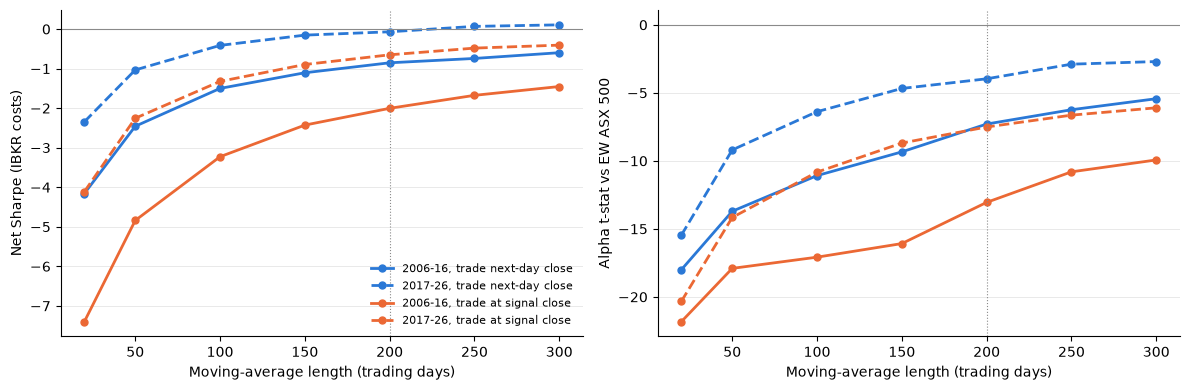

In [14]:
rows = {}
for n in [20, 50, 100, 150, 200, 250, 300]:
    s_n = ma_crossover(df, n)
    for lag in [1, 2]:
        bt = backtest_drift(s_n, df, lag=lag)
        for per, sl in PERIODS[:2]:
            st = stats(bt["net"].loc[sl], ew)
            st["gross_sharpe"] = stats(bt["gross"].loc[sl])["sharpe"]
            st["turnover"] = bt["turnover"].loc[sl].mean()
            st["cost_pa"] = bt["cost"].loc[sl].mean() * TRADING_DAYS
            rows[(n, lag, per)] = st
lengths = pd.DataFrame(rows).T.rename_axis(["MA length", "lag", "period"])
lengths.to_csv(RESULTS / "08_ma_lengths.csv")
display(lengths.xs(2, level="lag")[["sharpe", "gross_sharpe", "alpha", "alpha_t", "turnover", "cost_pa"]].unstack("period").round(3))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, (col, label) in zip(axs, [("sharpe", "Net Sharpe (IBKR costs)"), ("alpha_t", "Alpha t-stat vs EW ASX 500")]):
    for (lag, per), (c, ls) in {(2, "2006-16"): (BLUE, "-"), (2, "2017-26"): (BLUE, "--"), (1, "2006-16"): (ORANGE, "-"), (1, "2017-26"): (ORANGE, "--")}.items():
        g = lengths.xs((lag, per), level=("lag", "period"))[col]
        ax.plot(g.index, g.values, color=c, ls=ls, marker="o", ms=5, lw=2, label=f"{per}, trade {'at signal' if lag == 1 else 'next-day'} close")
    ax.axhline(0, color=GREY, lw=0.8)
    ax.axvline(MA, color=GREY, lw=0.8, ls=":")
    ax.set_xlabel("Moving-average length (trading days)")
    ax.set_ylabel(label)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", lw=0.6)
axs[0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "ma_lengths.png", dpi=130)
plt.show()

* **Nothing special about 200 days.** Every length from 20 to 300 has a negative alpha after costs in both periods. Shorter averages are much worse because they trade more (a 20-day average costs over 40% a year).
* Longer averages lose less, since turnover falls, but even 300 days has alpha of −15% and −5%.
* Before costs (`gross_sharpe`), 2006–16 is negative or flat at every length and 2017–26 is positive at every length. The rule has no stable edge of its own; it mostly reflects the market it is in.

## 10. A market filter instead? The index's own 200-day average

A common use of the 200-day average is on the *index*: hold stocks only while the market is above its average. For comparison, this holds the whole equal-weight ASX 500 when the All Ords is above its own 200-day average (decided at the previous close, traded at the next) and cash otherwise. It shows whether the stock-by-stock rule adds anything beyond timing the market.

In [15]:
level = (1 + aord.fillna(0)).cumprod()
market_on = (level > level.rolling(MA).mean()).astype(float)
timed_signal = df["member"].astype(float).mul(market_on, axis=0)
bt_timed = backtest_drift(timed_signal, df)
filt = report({"MA crossover, stock by stock": bt_final, "EW ASX 500 held only when All Ords > its 200-day average": bt_timed}, ew)
filt.to_csv(RESULTS / "09_market_filter.csv")
print(f"market filter invested {market_on.loc['2006':].mean():.0%} of days; correlation of the two strategies' daily returns: "
      f"{strat.loc['2006':].corr(bt_timed['net'].loc['2006':]):.2f}")
filt[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "cost_pa"]]

market filter invested 68% of days; correlation of the two strategies' daily returns: 0.64


ann_ret  ann_vol  sharpe  max_dd  alpha  alpha_t  cost_pa
strategy                                           period                                                            
MA crossover, stock by stock                       2006-16   -0.149    0.175  -0.852  -0.880 -0.196   -7.293    0.144
                                                   2017-26   -0.011    0.168  -0.068  -0.484 -0.082   -3.967    0.123
                                                   FULL      -0.084    0.172  -0.492  -0.919 -0.143   -8.150    0.134
EW ASX 500 held only when All Ords > its 200-da... 2006-16    0.053    0.110   0.476  -0.432  0.032    0.864    0.035
                                                   2017-26    0.043    0.114   0.374  -0.336  0.010    0.304    0.038
                                                   FULL       0.048    0.112   0.427  -0.432  0.022    0.863    0.036

Applying the 200-day average to the **index** instead, and holding the whole equal-weight universe only while the All Ords is above its average, is a different picture: about 5% a year at 11% volatility with a −43% drawdown, against −68% for buy-and-hold. It earns less than buy-and-hold (7.2% a year) and has no significant alpha (t = 0.9), but it trades rarely, so costs take about 3.6% a year instead of 13%. The 200-day average is more useful as a market-risk switch than as a stock-by-stock signal.

## 11. Momentum filter: the crossover on past winners only

Most of the whipsaw comes from stocks drifting sideways around their average. This section restricts the rule to stocks that have been trending strongly:

* **Filter:** at the end of each quarter, rank the ASX 500 members by their return over the previous 12 months, **skipping the most recent month** (the standard "12-1" momentum measure). The **top 10%** form the tradable list for the next quarter.
* **At each refresh:** a stock that drops out of the top 10% has its position closed. A stock that stays in keeps any open position.
* **Within the list** the crossover rule is unchanged, in two readings:
  * **A. Strict cross:** buy only on a fresh cross from below the 200-day average. A winner that is already above its average when it joins the list is not bought until it dips below and crosses back.
  * **B. Above the average:** hold any listed stock while its close is above its 200-day average, buying at the refresh if it is already above. Sell when it closes below.
* **C. Filter only:** hold every listed stock for the quarter, with no moving-average rule. This separates what the momentum filter contributes from what the average adds.

stocks on the list each quarter: 43;  share of listed stock-days above the 200-day average: 73%


,names held,days in cash,trades,median days held,win rate
A. Top-decile momentum + strict MA cross,6.030,0.020,"2,874.000",3.000,0.300
B. Top-decile momentum + held while above MA,31.230,0.010,"4,510.000",8.000,0.320
C. Top-decile momentum only (no MA rule),43.020,0.010,"1,868.000",66.000,0.400
"All stocks, strict MA cross (sections 4-10)",191.330,0.000,"41,450.000",3.000,0.290


ann_ret  ann_vol  sharpe  max_dd  alpha  alpha_t  turnover  cost_pa
strategy                                     period                                                                      
A. Top-decile momentum + strict MA cross     2006-16   -0.667    0.411  -1.622  -1.000 -0.717   -6.622     0.282    0.350
                                             2017-26   -0.512    0.444  -1.153  -0.998 -0.624   -5.500     0.338    0.556
                                             FULL      -0.594    0.427  -1.391  -1.000 -0.671   -8.544     0.308    0.447
B. Top-decile momentum + held while above MA 2006-16   -0.035    0.257  -0.136  -0.731 -0.093   -1.869     0.089    0.103
                                             2017-26    0.103    0.314   0.329  -0.642 -0.019   -0.359     0.086    0.136
                                             FULL       0.030    0.285   0.105  -0.828 -0.057   -1.523     0.087    0.119
C. Top-decile momentum only (no MA rule)     2006-16    0.075    0.251   0.301  -0.646  0.012    0.321     0.017    0.020
                                             2017-26    0.182    0.304   0.599  -0.595  0.058    1.346     0.017    0.028
                                             FULL       0.126    0.277   0.453  -0.646  0.035    1.187     0.017    0.024
All stocks, strict MA cross (sections 4-10)  2006-16   -0.149    0.175  -0.852  -0.880 -0.196   -7.293     0.135    0.144
                                             2017-26   -0.011    0.168  -0.068  -0.484 -0.082   -3.967     0.114    0.123
                                             FULL      -0.084    0.172  -0.492  -0.919 -0.143   -8.150     0.125    0.134

Before costs:


ann_ret  sharpe  alpha  alpha_t
A. Top-decile momentum + strict MA cross     2006-16   -0.317  -0.774 -0.366   -3.559
                                             2017-26    0.044   0.100 -0.068   -0.626
                                             FULL      -0.147  -0.345 -0.224   -2.986
B. Top-decile momentum + held while above MA 2006-16    0.068   0.265  0.010    0.204
                                             2017-26    0.239   0.761  0.116    2.195
                                             FULL       0.149   0.521  0.061    1.671
C. Top-decile momentum only (no MA rule)     2006-16    0.096   0.382  0.033    0.847
                                             2017-26    0.211   0.692  0.087    2.014
                                             FULL       0.150   0.540  0.059    2.006
All stocks, strict MA cross (sections 4-10)  2006-16   -0.005  -0.031 -0.052   -2.074
                                             2017-26    0.112   0.668  0.042    2.197
                                             FULL       0.050   0.290 -0.009   -0.537

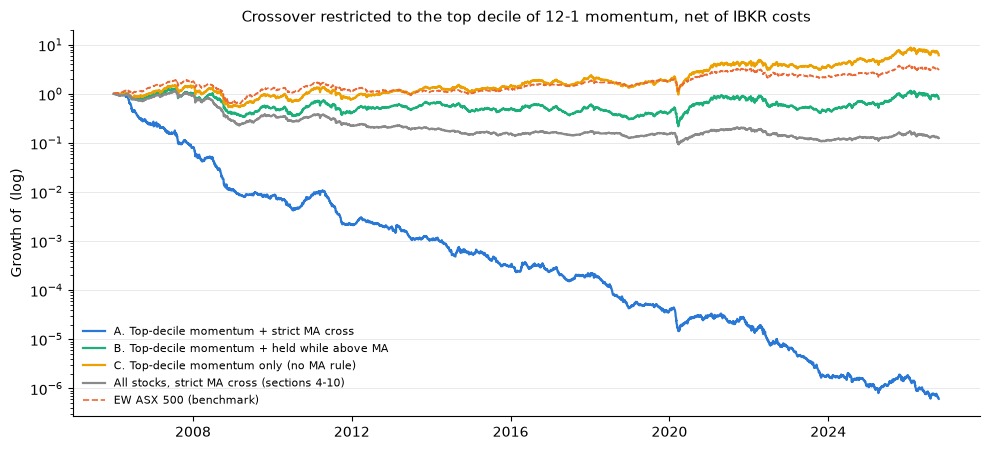

In [16]:
def momentum_top_decile(df, lookback=252, skip=21, top=0.10):
    # True while a stock is on the tradable list: top decile of 12-1 momentum at the last quarter end, applied from the next day
    px, days = df["adj"], df["adj"].index
    mom = px.shift(skip) / px.shift(lookback) - 1
    quarter_end = days.to_series().groupby(days.to_period("Q")).max().values
    pct = mom.where(df["member"]).loc[quarter_end].rank(axis=1, pct=True)
    listed = (pct > 1 - top).astype(float).reindex(days).shift(1).ffill().fillna(0.0).astype(bool)
    return listed & df["member"]


listed = momentum_top_decile(df)
above = df["adj"] > df["adj"].rolling(MA, min_periods=MA).mean()
mom_signals = {"A. Top-decile momentum + strict MA cross": ma_crossover(df, MA, eligible=listed),
               "B. Top-decile momentum + held while above MA": (above & listed).astype(float),
               "C. Top-decile momentum only (no MA rule)": listed.astype(float),
               "All stocks, strict MA cross (sections 4-10)": s}
mom_bts, extra = {}, {}
for name, sig in mom_signals.items():
    mom_bts[name], Hm = backtest_drift(sig, df, holdings=True)
    tl = trade_log(sig, df)
    tl = tl[tl["entry"] >= "2006-01-01"]
    Hm = Hm.loc["2006":]
    extra[name] = {"names held": (Hm > 0).sum(axis=1).mean(), "days in cash": (Hm.sum(axis=1) == 0).mean(),
                   "trades": len(tl), "median days held": tl["days"].median(), "win rate": (tl["ret"] > 0).mean()}
mom_table = report(mom_bts, ew)
mom_table.to_csv(RESULTS / "10_momentum_filter.csv")
print(f"stocks on the list each quarter: {listed.loc['2006':].sum(axis=1).mean():.0f};  "
      f"share of listed stock-days above the 200-day average: {(above & listed).loc['2006':].sum().sum() / listed.loc['2006':].sum().sum():.0%}")
display(pd.DataFrame(extra).T.round(2))
display(mom_table[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "turnover", "cost_pa"]])

gross_alpha = pd.DataFrame({(name, per): stats(bt["gross"].loc[sl], ew)[["ann_ret", "sharpe", "alpha", "alpha_t"]]
                            for name, bt in mom_bts.items() for per, sl in PERIODS}).T
print("Before costs:")
display(gross_alpha.round(3))

fig, ax = plt.subplots(figsize=(10, 4.6))
for (name, bt), c in zip(mom_bts.items(), [BLUE, AQUA, YELLOW, GREY]):
    ax.plot((1 + bt["net"].loc["2006":]).cumprod(), color=c, lw=1.6, label=name)
ax.plot((1 + ew.loc["2006":]).cumprod(), color=ORANGE, lw=1.2, ls="--", label="EW ASX 500 (benchmark)")
ax.set_yscale("log")
ax.set_ylabel("Growth of  (log)")
ax.set_title("Crossover restricted to the top decile of 12-1 momentum, net of IBKR costs", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "momentum_filter.png", dpi=130)
plt.show()

**The momentum filter does not rescue the crossover.**

| After IBKR costs | Return/yr 2006–16 | Return/yr 2017–26 | Costs/yr | Names held |
|---|---|---|---|---|
| A. Winners + strict cross from below | −67% | −51% | 35–56% | 6 |
| B. Winners + held while above the average | −3.5% | +10.3% | 10–14% | 31 |
| C. Winners only, no average rule | +7.5% | +18.2% | 2–3% | 43 |
| All stocks, strict cross | −14.9% | −1.1% | 12–14% | 191 |
| *EW ASX 500 (benchmark)* | *+5.4%* | *+9.2%* | | |

* **A (the rule as specified) is the worst version.** A top-decile winner is above its 200-day average 73% of the time, so it rarely produces a cross *from below*. Only about 6 of the 43 listed stocks are held at once, and they are the winners that have just stumbled below their average and bounced. The median trade still lasts 3 days. With so few names, each entry or exit reshuffles a large share of the book: turnover is about 30% of capital a day and costs take 35–56% a year. It loses before costs too (−15% a year).
* **B is the natural reading and is much better, but still behind the benchmark.** Holding listed stocks while they are above the average keeps about 31 names. Before costs it earns 14.9% a year (alpha 6.1%, t = 1.7). Costs of 10–14% a year take that away: net alpha is −9.3% and −1.9%.
* **C shows where the return comes from.** Simply holding the top-decile winners for the quarter earns 7.5% and 18.2% a year after costs of 2–3%, ahead of the benchmark in both halves, though the alpha is not statistically significant (3.5% a year, t = 1.2) and the drawdown is −65%.
* **So the momentum filter adds value and the moving-average rule subtracts it.** B and C earn the same before costs (about 15% a year). The average rule adds about 2,600 extra trades and 10 points of cost a year, and does not reduce the drawdown (−83% for B against −65% for C).

## 12. Monte Carlo: strategy vs random buy-and-hold

**Question:** is the strategy better than just buying a random basket of ASX 500 stocks and holding it?

**Setup**
* Each simulation picks **K** stocks at random from the ASX 500 members on the start date, buys them equal weight (paying commission and half-spread once), and holds them to the end with no rebalancing.
* 1,000 simulations for each K: K=30 (a typical concentrated investor) and K = the strategy's average number of longs.
* Two windows: 2006– and 2017–.
* Random picks come from stocks still listed today, the **same survivorship bias** as the strategy.

**Control.** The same random picks are also reset to equal weight **every day**, with no costs. It is not investable, and it measures how much daily resetting on closing prices inflates results.

In [17]:
def metrics(r, bench):
    # vectorised annual metrics for a days x portfolios matrix
    r = np.asarray(r)
    r = r[:, None] if r.ndim == 1 else r
    eq = np.cumprod(1 + r, axis=0)
    b = np.asarray(bench)
    bc = b - b.mean()
    beta = (bc[:, None] * (r - r.mean(0))).sum(0) / (bc ** 2).sum()
    vol = r.std(0, ddof=1) * np.sqrt(TRADING_DAYS)
    return pd.DataFrame({
        "cagr": eq[-1] ** (TRADING_DAYS / len(r)) - 1,
        "ann_vol": vol,
        "sharpe": r.mean(0) * TRADING_DAYS / vol,
        "max_dd": (eq / np.maximum.accumulate(eq, axis=0) - 1).min(0),
        "alpha_aord": (r.mean(0) - beta * b.mean()) * TRADING_DAYS,
        "beta_aord": beta,
    })


def random_baskets(start, k, n_sims, rng):
    # n_sims x stocks equal start weights on K random members
    pool = np.flatnonzero(df["member"].loc[start:].iloc[0].values)
    w0 = np.zeros((n_sims, df["member"].shape[1]))
    for i in range(n_sims):
        w0[i, rng.choice(pool, size=k, replace=False)] = 1 / k
    return w0


def buy_and_hold(growth, w0, cost=0.0):
    # days x sims value of $1 bought at start weights w0 and never traded, and its daily returns
    value = growth @ w0.T * (1 - cost)
    return value, np.vstack([value[:1] - 1, value[1:] / value[:-1] - 1])


N_SIMS, COST = 1000, 23e-4          # one purchase: 8 bps commission + a typical 15 bps half-spread
WINDOWS = {"2006-": "2006-01-03", "2017-": "2017-01-03"}
k_match = int(round((s > 0).sum(axis=1).loc["2006":].mean()))
ret0, aord0 = df["ret"].fillna(0.0), aord.fillna(0.0)
rng = np.random.default_rng(7)

rows, dists, fans = [], {}, {}
for wname, start in WINDOWS.items():
    r_win, b_win = ret0.loc[start:], aord0.loc[start:]
    growth = np.cumprod(1 + r_win.values, axis=0)
    for k in [30, k_match]:
        w0 = random_baskets(start, k, N_SIMS, rng)
        value, daily = buy_and_hold(growth, w0, COST)
        dists[(wname, k)], fans[(wname, k)] = metrics(daily, b_win), value
        reset = metrics(r_win.values @ w0.T, b_win)                  # control: daily reset to equal weight
        for label, m in [(f"random B&H, K={k}", dists[(wname, k)]), (f"control: daily-reset EW, K={k}", reset)]:
            for q, row in m.quantile([0.05, 0.5, 0.95]).iterrows():
                rows.append({"window": wname, "portfolio": label, "stat": f"p{int(q * 100)}", **row})
    ms = metrics(strat.loc[start:].values, b_win).iloc[0]
    rows.append({"window": wname, "portfolio": "MA crossover long-only", "stat": "value", **ms})
    for k in [30, k_match]:
        rows.append({"window": wname, "portfolio": "MA crossover long-only", "stat": f"percentile vs K={k}",
                     **{c: (dists[(wname, k)][c] < ms[c]).mean() * 100 for c in ["cagr", "sharpe", "max_dd", "alpha_aord"]}})

mc = pd.DataFrame(rows)
mc.to_csv(RESULTS / "11_mc_buyhold.csv", index=False)
mc_p = pd.DataFrame({wname: {f"p_{c}": (1 + (dists[(wname, k_match)][c] >= metrics(strat.loc[start:].values, aord0.loc[start:]).iloc[0][c]).sum())
                             / (1 + N_SIMS) for c in ["cagr", "sharpe", "max_dd", "alpha_aord"]} for wname, start in WINDOWS.items()}).T
mc_p.to_csv(RESULTS / "11a_mc_pvalues.csv")
print(f"K matched to the strategy's average long count: {k_match}")
display(mc.drop(columns=["ann_vol", "beta_aord"]).set_index(["window", "portfolio", "stat"]).loc[lambda d: d.index.get_level_values("portfolio").str.contains(f"K={k_match}|MA crossover")].round(3))
print("p-values: share of random baskets (K matched) that did at least as well")
mc_p.round(3)

K matched to the strategy's average long count: 191


cagr  sharpe  max_dd  alpha_aord
window portfolio                      stat                                                  
2006-  random B&H, K=191              p5                   0.069   0.488  -0.682       0.043
                                      p50                  0.085   0.573  -0.659       0.059
                                      p95                  0.097   0.635  -0.634       0.069
       control: daily-reset EW, K=191 p5                   0.291   1.875  -0.546       0.237
                                      p50                  0.314   1.993  -0.524       0.255
                                      p95                  0.338   2.100  -0.502       0.273
       MA crossover long-only         value               -0.095  -0.492  -0.919      -0.119
                                      percentile vs K=30   0.000   0.000   0.000       0.000
                                      percentile vs K=191  0.000   0.000   0.000       0.000
2017-  random B&H, K=191              p5                   0.065   0.447  -0.460       0.026
                                      p50                  0.085   0.560  -0.434       0.045
                                      p95                  0.103   0.650  -0.411       0.061
       control: daily-reset EW, K=191 p5                   0.208   1.414  -0.437       0.157
                                      p50                  0.233   1.542  -0.417       0.178
                                      p95                  0.259   1.672  -0.397       0.199
       MA crossover long-only         value               -0.025  -0.068  -0.484      -0.060
                                      percentile vs K=30   0.000   0.000  45.500       0.000
                                      percentile vs K=191  0.000   0.000   0.000       0.000

p-values: share of random baskets (K matched) that did at least as well


,p_cagr,p_sharpe,p_max_dd,p_alpha_aord
2006-,1.000,1.000,1.000,1.000
2017-,1.000,1.000,1.000,1.000


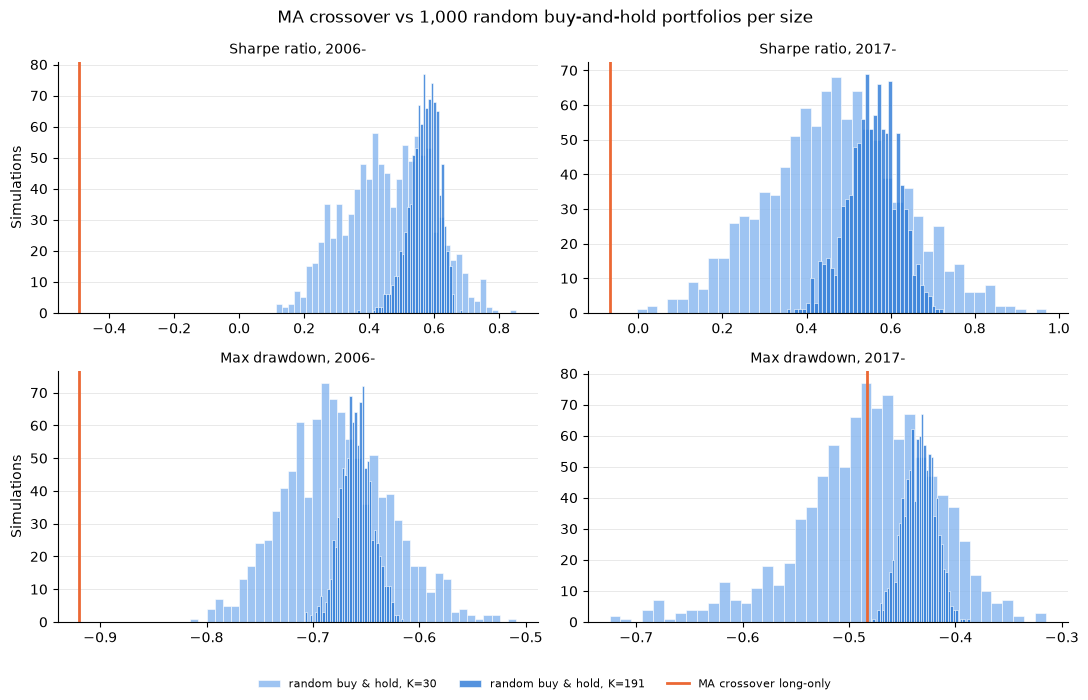

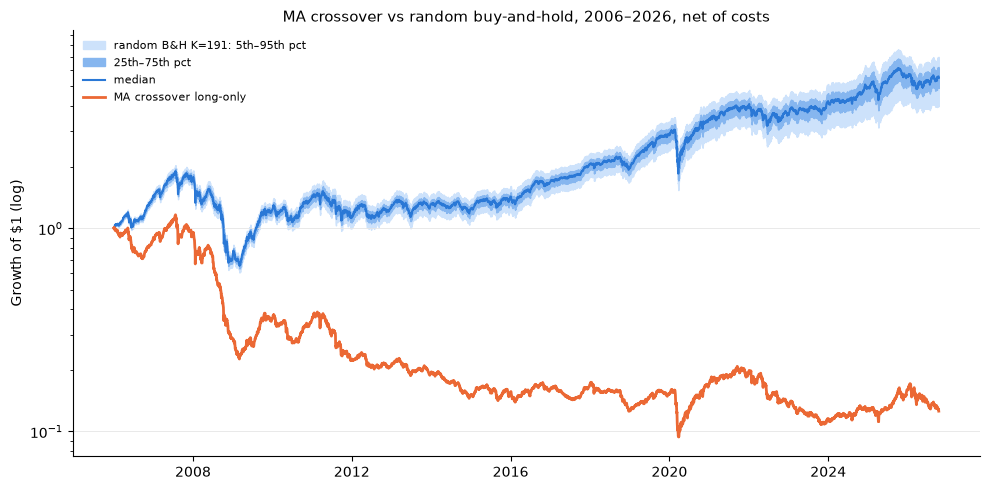

In [18]:
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for i, wname in enumerate(WINDOWS):
    for j, (col, label) in enumerate([("sharpe", "Sharpe ratio"), ("max_dd", "Max drawdown")]):
        ax = axs[j, i]
        for k, c in [(30, BLUE_MID), (k_match, BLUE)]:
            ax.hist(dists[(wname, k)][col], bins=40, color=c, alpha=0.8, edgecolor="white", linewidth=0.5,
                    label=f"random buy & hold, K={k}")
        ax.axvline(metrics(strat.loc[WINDOWS[wname]:].values, aord0.loc[WINDOWS[wname]:]).iloc[0][col],
                   color=ORANGE, lw=2, label="MA crossover long-only")
        ax.set_title(f"{label}, {wname}", fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="#e5e5e5", lw=0.6)
        ax.set_axisbelow(True)
axs[0, 0].set_ylabel("Simulations")
axs[1, 0].set_ylabel("Simulations")
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8, frameon=False)
fig.suptitle(f"MA crossover vs {N_SIMS:,} random buy-and-hold portfolios per size", fontsize=12)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(RESULTS / "mc_distributions.png", dpi=130)
plt.show()

value = fans[("2006-", k_match)]
idx = ret0.loc[WINDOWS["2006-"]:].index
fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(idx, np.percentile(value, 5, axis=1), np.percentile(value, 95, axis=1), color=BLUE_LIGHT,
                label=f"random B&H K={k_match}: 5th–95th pct")
ax.fill_between(idx, np.percentile(value, 25, axis=1), np.percentile(value, 75, axis=1), color=BLUE_MID, label="25th–75th pct")
ax.plot(idx, np.median(value, axis=1), color=BLUE, lw=1.5, label="median")
ax.plot(idx, (1 + strat.loc[WINDOWS["2006-"]:]).cumprod(), color=ORANGE, lw=2, label="MA crossover long-only")
ax.set_yscale("log")
ax.set_ylabel("Growth of $1 (log)")
ax.set_title("MA crossover vs random buy-and-hold, 2006–2026, net of costs", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
ax.legend(fontsize=8, frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(RESULTS / "mc_equity_fan.png", dpi=130)
plt.show()

* The crossover book is **worse than every one of the 1,000 random baskets** on return, Sharpe, drawdown and alpha, in both windows (p = 1.0). Buying 191 random members and never trading them earned about 8.5% a year.
* **Control:** random stocks reset to equal weight daily show a Sharpe near 2 with no skill, which is the daily-reset artifact the drift engine avoids.

## 13. Is the edge statistically significant?

Beating random baskets shows the strategy beat random stock *selection* in this one history. Two further tests:

### 13a. Signal-shift permutation test (does the *timing* matter?)

* Each stock's signal series is shifted forward by a random number of days (at least a year), wrapping around the end.
* This keeps each stock's number of trades and holding periods, but breaks the link between the signal and the real crossovers.
* Shifted signals are re-masked to the universe, then backtested with the same engine and costs.

200 permutations give a p-value floor of 1/201 ≈ 0.005. (This cell takes a few minutes.)

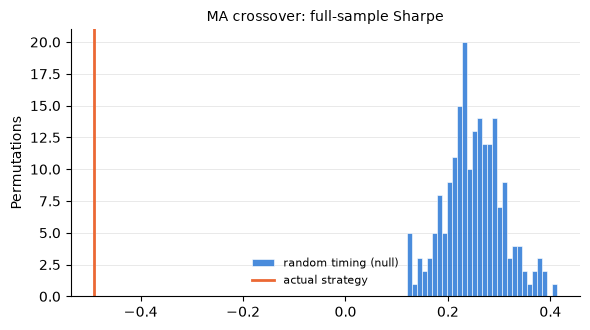

,observed Sharpe,null p5,null median,null p95,p-value
MA crossover long-only,-0.492,0.152,0.249,0.347,1.000


In [19]:
N_PERM = 200
prng = np.random.default_rng(5)
mem = df["member"].values
sv0 = s.values
null = []
for _ in range(N_PERM):
    sv = np.empty_like(sv0)
    for j in range(sv0.shape[1]):
        sv[:, j] = np.roll(sv0[:, j], prng.integers(252, len(sv0) - 252))
    sp = pd.DataFrame(np.where(mem, sv, 0.0), s.index, s.columns)
    null.append(stats(backtest_drift(sp, df)["net"].loc["2006":])["sharpe"])
null = np.array(null)
obs = stats(strat.loc["2006":])["sharpe"]
perm_table = pd.DataFrame({"MA crossover long-only": {
    "observed Sharpe": obs, "null p5": np.percentile(null, 5), "null median": np.median(null),
    "null p95": np.percentile(null, 95), "p-value": (1 + (null >= obs).sum()) / (1 + N_PERM)}}).T
perm_table.to_csv(RESULTS / "11b_permutation.csv")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(null, bins=30, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.5, label="random timing (null)")
ax.axvline(obs, color=ORANGE, lw=2, label="actual strategy")
ax.set_title("MA crossover: full-sample Sharpe", fontsize=10)
ax.set_ylabel("Permutations")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
ax.set_axisbelow(True)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "permutation_test.png", dpi=130)
plt.show()
perm_table

Shuffling the timing of each stock's signals gives a *better* result than the real rule: the null Sharpe has a median of 0.25, against −0.49 for the strategy (p = 1.0). The real crossovers are worse than random entry and exit dates with the same number of trades, because a cross tends to be followed by a short-term reversal.

### 13b. Paired stationary block bootstrap (does the edge survive a different history?)

* Resample the daily history in **blocks** of random length (mean 20 days; the stationary bootstrap of Politis & Romano). Blocks keep volatility clustering and autocorrelation intact.
* The resample is **paired**: the same days are drawn for the strategy and the benchmark.
* In each of 2,000 resamples, compute the difference in Sharpe (or mean return) between the strategy and (i) the drifting equal-weight ASX 500, and (ii) the median of 200 random buy-and-hold portfolios (K matched) on the same resampled days.
* The 95% interval is the 2.5th–97.5th percentile of those differences. The two-sided p-value is twice the share of resamples on the wrong side of zero (Ledoit & Wolf 2008).

The last rows give the **probabilistic Sharpe ratio** of the active return (strategy minus the equal-weight ASX 500): the probability that its true mean is above zero, allowing for skew and fat tails.

In [20]:
from scipy.stats import kurtosis, norm, skew


def stationary_bootstrap_idx(T, B, mean_block, rng):
    idx = np.empty((B, T), dtype=np.int64)
    idx[:, 0] = rng.integers(0, T, B)
    jump = rng.random((B, T)) < 1 / mean_block
    fresh = rng.integers(0, T, (B, T))
    for t in range(1, T):
        idx[:, t] = np.where(jump[:, t], fresh[:, t], (idx[:, t - 1] + 1) % T)
    return idx


def ann_sharpe(x, axis=0):
    return x.mean(axis) / x.std(axis) * np.sqrt(TRADING_DAYS)


def psr(r):
    r = r.dropna()
    sr = r.mean() / r.std()
    g3, g4 = skew(r), kurtosis(r, fisher=False)
    return norm.cdf(sr * np.sqrt(len(r) - 1) / np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2))


B, BLOCK, N_RAND = 2000, 20, 200
brng = np.random.default_rng(11)
TESTS = ("ΔSharpe vs EW ASX 500", "ΔSharpe vs median random B&H", "Δann. return vs median random B&H")
boot_rows = {}
for wname, start in WINDOWS.items():
    r_win = ret0.loc[start:]
    growth = np.cumprod(1 + r_win.values, axis=0)
    rand = buy_and_hold(growth, random_baskets(start, k_match, N_RAND, brng))[1]     # T x N_RAND random B&H daily returns
    e, x = ew.loc[start:].values, strat.loc[start:].values
    diffs = {t: [] for t in TESTS}
    for row in stationary_bootstrap_idx(len(r_win), B, BLOCK, brng):
        xs, rs = x[row], rand[row]
        sx = ann_sharpe(xs)
        diffs[TESTS[0]].append(sx - ann_sharpe(e[row]))
        diffs[TESTS[1]].append(sx - np.median(ann_sharpe(rs)))
        diffs[TESTS[2]].append((xs.mean() - np.median(rs.mean(0))) * TRADING_DAYS)
    observed = {TESTS[0]: ann_sharpe(x) - ann_sharpe(e), TESTS[1]: ann_sharpe(x) - np.median(ann_sharpe(rand)),
                TESTS[2]: (x.mean() - np.median(rand.mean(0))) * TRADING_DAYS}
    for test, arr in diffs.items():
        arr = np.array(arr)
        boot_rows[(wname, test)] = {"observed": observed[test], "ci_low": np.percentile(arr, 2.5), "ci_high": np.percentile(arr, 97.5),
                                    "p_value": max(2 * min((arr <= 0).mean(), (arr >= 0).mean()), 1 / B)}
boot = pd.DataFrame(boot_rows).T
boot.to_csv(RESULTS / "11c_block_bootstrap.csv")
active = strat - ew
psr_table = pd.DataFrame({per: {"information ratio": ann_sharpe(active.loc[sl]), "probability active return > 0": psr(active.loc[sl])}
                          for per, sl in PERIODS}).T
psr_table.to_csv(RESULTS / "11d_psr.csv")
display(boot)
psr_table

observed  ci_low  ci_high  p_value
2006- ΔSharpe vs EW ASX 500                -0.865  -1.106   -0.645    0.001
      ΔSharpe vs median random B&H         -1.069  -1.380   -0.789    0.001
      Δann. return vs median random B&H    -0.180  -0.230   -0.134    0.001
2017- ΔSharpe vs EW ASX 500                -0.521  -0.772   -0.266    0.001
      ΔSharpe vs median random B&H         -0.630  -0.922   -0.349    0.001
      Δann. return vs median random B&H    -0.108  -0.159   -0.060    0.001

,information ratio,probability active return > 0
2006-16,-2.578,0.000
2017-26,-1.306,0.000
FULL,-1.977,0.000


The shortfall is statistically significant, not noise: the Sharpe and the return are below the equal-weight ASX 500 and below random buy-and-hold in both windows (p = 0.001 for every test), and the probability that the active return is positive is zero.

## 14. Hedging the market with the index

The book is fully invested in equities, so most of its risk is the market's. Shorting the index against it in proportion to its beta (in practice with SPI 200 futures) leaves the part that the crossover rule adds.

* Each day the hedge ratio is the book's beta to the All Ords over the previous 126 days, using information up to yesterday only.
* The hedge return is $-\beta_{t-1}\, r^{index}_t$, with 2 bps charged on changes in the hedge ratio.
* ^AORD is a price index, so futures roll, dividends and carry are ignored; that is a simplification.

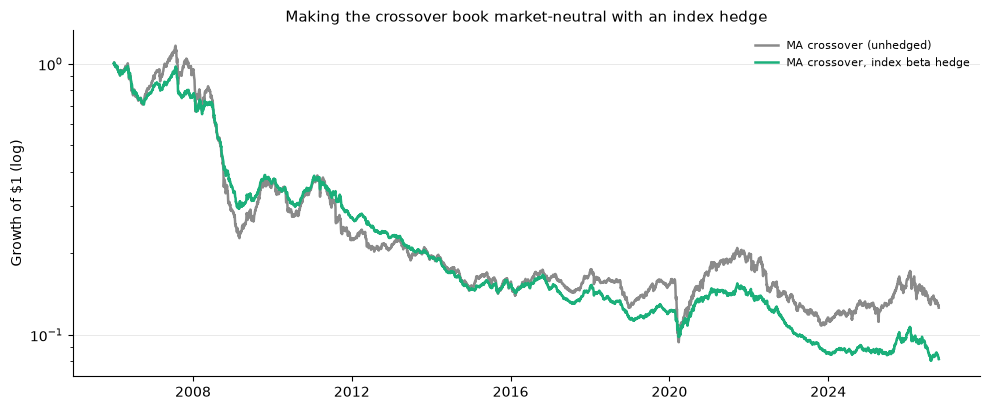

ann_ret  ann_vol  sharpe  max_dd  alpha  alpha_t  beta_aord
MA crossover (unhedged)        2006-16   -0.149    0.175  -0.852  -0.880 -0.196   -7.293      0.740
                               2017-26   -0.011    0.168  -0.068  -0.484 -0.082   -3.967      0.878
                               FULL      -0.084    0.172  -0.492  -0.919 -0.143   -8.150      0.793
MA crossover, index beta hedge 2006-16   -0.165    0.116  -1.431  -0.859 -0.180   -5.127     -0.024
                               2017-26   -0.056    0.105  -0.538  -0.481 -0.080   -2.817     -0.019
                               FULL      -0.114    0.111  -1.031  -0.921 -0.133   -5.763     -0.022

In [21]:
mkt = aord.fillna(0.0)
win = 126
cov = (strat * mkt).rolling(win, min_periods=60).mean() - strat.rolling(win, min_periods=60).mean() * mkt.rolling(win, min_periods=60).mean()
hedge_beta = (cov / mkt.rolling(win, min_periods=60).var()).shift(1).fillna(0.9)
hedged = strat - hedge_beta * mkt - hedge_beta.diff().abs().fillna(0) * 2e-4

hedge_bts = {"MA crossover (unhedged)": strat, "MA crossover, index beta hedge": hedged}
hedge_table = pd.DataFrame({(name, per): pd.concat([stats(sr.loc[sl], ew).drop("info_ratio"),
                                                    stats(sr.loc[sl], aord)[["beta"]].rename({"beta": "beta_aord"})])
                            for name, sr in hedge_bts.items() for per, sl in PERIODS}).T
hedge_table.to_csv(RESULTS / "12_beta_hedge.csv")

fig, ax = plt.subplots(figsize=(10, 4.2))
for (name, sr), c in zip(hedge_bts.items(), [GREY, AQUA]):
    ax.plot((1 + sr.loc["2006":]).cumprod(), color=c, lw=1.8, label=name)
ax.set_yscale("log")
ax.set_ylabel("Growth of $1 (log)")
ax.set_title("Making the crossover book market-neutral with an index hedge", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "beta_hedge.png", dpi=130)
plt.show()
hedge_table[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "beta_aord"]]

Hedging removes the market exposure (beta about 0) and leaves the rule's own contribution, which is negative: −16.5% a year in 2006–16 and −5.6% in 2017–26. There is nothing here worth hedging.

## 15. Conclusions

In [22]:
summary = final[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "beta_aord", "turnover", "cost_pa"]]
summary.style.format({"ann_ret": "{:.1%}", "ann_vol": "{:.1%}", "sharpe": "{:.2f}", "max_dd": "{:.1%}", "alpha": "{:.1%}",
                      "alpha_t": "{:.1f}", "beta_aord": "{:.2f}", "turnover": "{:.2%}", "cost_pa": "{:.1%}"}, na_rep="")

**Findings**
1. **A long-only 200-day moving-average crossover on ASX 500 stocks loses money.** After IBKR costs it returns −14.9% a year in 2006–16 and −1.1% in 2017–26, against +5.4% and +9.2% for the equal-weight ASX 500, with a −92% drawdown.
2. **Whipsaw is the cause.** The median trade lasts 3 days and 63% last five days or less. The book turns over 12.5% of its capital a day and costs take 12–14% a year, most of it bid-ask spread.
3. **There is no reliable edge underneath.** Before costs the alpha is −5% a year in the first half and +4% in the second.
4. **It is not the 200-day choice.** Every length from 20 to 300 days loses to the benchmark after costs.
5. **It is worse than doing nothing.** It loses to all 1,000 random buy-and-hold baskets and to its own signals with the timing shuffled.
6. **The index version is the usable one.** Holding the universe only while the All Ords is above its 200-day average cuts the drawdown from −68% to −43% at a third of the cost, though it does not beat buy-and-hold on return.
7. **A momentum filter does not fix it.** Restricting the rule to the top decile of 12-1 momentum, refreshed quarterly, makes the strict-cross version far worse (about 6 names held, costs of 35–56% a year). Holding the winners while they are above their average earns 15% a year before costs but only 3% after. Holding the winners with no average rule does best (12.6% a year after costs).

**Why it differs from the archived channel-breakout study.** That rule bought a 200-day *high* and sold a 50-day low: entries were rare, exits were far from the entry, and the median holding period was months. A moving-average cross triggers every time the price wobbles through the line, so the same trend information comes with many times the trading.

**Caveats**
* **Survivorship:** only today's listed companies are included, which flatters any long book; the benchmark has the same bias.
* **Spread assumption:** half of one tick per trade. Thin small caps often quote wider, which would make the result worse.
* **Engine trimming:** each new entry is funded by trimming every other holding, which adds small trades. A design that funds entries from cash would trade less, but the 41,000 entry and exit trades would remain.
* **Data:** Yahoo errors were filtered (notebook 01), but some may remain.

**What could reduce the whipsaw (not tested here):** a band around the average (buy 3–5% above, sell 3–5% below); requiring the close to stay across the line for several days; checking the signal weekly or monthly instead of daily; or using two averages (for example 50-day crossing 200-day) in place of price crossing one.